Preprocessing for Screening Stage Cancer vs healthy

Import operating system, numpy, pandas, matplotlib, random libraries

In [1]:
# --- project-root bootstrap: make this notebook CWD-independent (auto-added) ---
import os as _os
_root = _os.path.abspath(_os.getcwd())
while not _os.path.exists(_os.path.join(_root, 'data', 'raw', 'Train_Set.csv')) and _root != _os.path.dirname(_root):
    _root = _os.path.dirname(_root)
_os.chdir(_root)
# --- end bootstrap ---
import numpy as np
import pandas as pd
import matplotlib as mp
import random

Set seed to ensure reproducability

In [2]:
random.seed(123)
np.random.seed(123)


Load train and test datatsets and carry out visualisation

In [3]:
trainp_data = pd.read_csv('data/raw/Train_Set.csv')
testp_data = pd.read_csv('data/raw/Test_Set.csv')
print(trainp_data.head(5)) # information on first five data points
print(testp_data.head(5)) # information on first five data points
print(trainp_data.shape) # dimensions of train data set
print(testp_data.shape) # dimensions of test data set
print(trainp_data.describe()) # statistical information on train data set
print(testp_data.describe()) # statistical information on test data set

   length_51  length_52  length_53  length_54  length_55  length_56  \
0   0.000152   0.000081   0.000087   0.000092   0.000099   0.000125   
1   0.006256   0.006413   0.006512   0.006469   0.006810   0.007070   
2   0.003783   0.003886   0.004063   0.004237   0.004481   0.004832   
3   0.004635   0.004471   0.004383   0.004829   0.004920   0.005056   
4   0.011315   0.010045   0.009795   0.009906   0.010630   0.011467   

   length_57  length_58  length_59  length_60  ...  length_392  length_393  \
0   0.000122   0.000115   0.000151   0.000167  ...    0.007396    0.007193   
1   0.007748   0.008088   0.008671   0.008835  ...    0.017830    0.017033   
2   0.004960   0.005605   0.005919   0.006480  ...    0.010957    0.010481   
3   0.005475   0.006158   0.007174   0.007697  ...    0.010032    0.008933   
4   0.013024   0.014853   0.016874   0.017501  ...    0.009118    0.008535   

   length_394  length_395  length_396  length_397  length_398  length_399  \
0    0.006973    0.006481  

         length_51    length_52    length_53    length_54    length_55  \
count  1034.000000  1034.000000  1034.000000  1034.000000  1034.000000   
mean      0.008011     0.007394     0.007398     0.007488     0.007869   
std       0.008406     0.007525     0.007509     0.007483     0.007873   
min       0.000025     0.000036     0.000023     0.000033     0.000036   
25%       0.001941     0.001862     0.001862     0.001946     0.002111   
50%       0.005219     0.004891     0.004954     0.005130     0.005282   
75%       0.011696     0.010996     0.010919     0.011181     0.011558   
max       0.057527     0.050626     0.050988     0.051242     0.053144   

         length_56    length_57    length_58    length_59    length_60  ...  \
count  1034.000000  1034.000000  1034.000000  1034.000000  1034.000000  ...   
mean      0.008487     0.009376     0.011120     0.013354     0.014610  ...   
std       0.008597     0.009672     0.011985     0.015066     0.016892  ...   
min       0.00003

Check for missing data points in train and test data

In [4]:
print(trainp_data.isna().sum()) # check how many data points missing
print(trainp_data.iloc[:, -1]) # view response variable (status of cancer)
print(trainp_data['class_label'].value_counts()) # inspect distribution of response variable (status of cancer)
print(testp_data.isna().sum()) # check how many data points missing
print(testp_data.iloc[:, -1]) # view response variable (status of cancer)
print(testp_data['class_label'].value_counts()) # inspect distribution of response variable (status of cancer)

length_51      0
length_52      0
length_53      0
length_54      0
length_55      0
              ..
length_397     0
length_398     0
length_399     0
length_400     0
class_label    0
Length: 351, dtype: int64
0                  healthy
1                  healthy
2                  healthy
3                  healthy
4                  healthy
               ...        
2188    early stage cancer
2189    early stage cancer
2190    early stage cancer
2191    early stage cancer
2192    early stage cancer
Name: class_label, Length: 2193, dtype: object
class_label
early stage cancer        781
screening stage cancer    490
mid stage cancer          453
late stage cancer         409
healthy                    60
Name: count, dtype: int64
length_51      0
length_52      0
length_53      0
length_54      0
length_55      0
              ..
length_397     0
length_398     0
length_399     0
length_400     0
class_label    0
Length: 351, dtype: int64
0                 healthy
1               

Remove irrelevant classes from train and test data that are not either healthy or screening stage cancer

In [5]:
trainp_data = trainp_data[(trainp_data['class_label'] == 'healthy') | (trainp_data['class_label'] == 'screening stage cancer')] # remove non he;lathy and non screening stage cancer classes
trainp_data.reset_index(drop=True, inplace=True)
print(trainp_data['class_label'].value_counts())
testp_data = testp_data[(testp_data['class_label'] == 'healthy') |
(testp_data['class_label'] == 'screening stage cancer')] # remove non he;lathy and non screening stage cancer classes
testp_data.reset_index(drop=True, inplace=True)
print(testp_data['class_label'].value_counts())

class_label
screening stage cancer    490
healthy                    60
Name: count, dtype: int64
class_label
screening stage cancer    230
healthy                    41
Name: count, dtype: int64


Extract independent and dependent features from train and test datasets

In [6]:
xvals_train = trainp_data.iloc[:, 0:350] # access train x values
yvals_train = trainp_data.iloc[:,350] # access train y values
xvals_test = testp_data.iloc[:, 0:350] # access test x values
yvals_test = testp_data.iloc[:, 350] # access test x values

Standardising x values in train and test dataset

In [7]:
from sklearn.preprocessing import StandardScaler
std_x = StandardScaler() # initialise StandardScaler
xvals_train_std = std_x.fit_transform(xvals_train) # standardise x values of train dataset
xvals_test_std = std_x.transform(xvals_test) # use transform (fit only on train) to avoid leakage # standardise x values of test dataset

Convert y variables to binary for test and train data set as neccessary

In [8]:
yvals_train_binary = yvals_train.map({'screening stage cancer': 1, 'healthy': 0}) # Convert "cancer" to 1 and "healthy" to 0
print(yvals_train_binary.unique())
yvals_test_binary = yvals_test.map({'screening stage cancer': 1, 'healthy': 0}) # Convert "cancer" to 1 and "healthy" to 0
print(yvals_train_binary.unique())

[0 1]
[0 1]


Technique to remove regressors:

Perform L1 (lasso) regularisation to logistic regression model to idenitify insignifcant regressors with coefficients equals to zero

In [9]:
from sklearn.linear_model import LogisticRegression
log_reg_l1 = LogisticRegression(penalty='l1', solver='liblinear', random_state=42)  # specify solver for L1 regularization
log_reg_l1.fit(xvals_train_std, yvals_train_binary)  # train model
significant_features_1 = list(xvals_train.columns[log_reg_l1.coef_[0] != 0]) # check if there are any signifcant features identified
insignificant_features_1 = list(xvals_train.columns[log_reg_l1.coef_[0] == 0]) # identify insignifcant features
print(len(insignificant_features_1) + len(significant_features_1)) # check if total number of features is 350
print(insignificant_features_1) # identify insiginficant features identified with this technique

350
['length_51', 'length_52', 'length_54', 'length_55', 'length_56', 'length_57', 'length_58', 'length_59', 'length_60', 'length_61', 'length_62', 'length_63', 'length_64', 'length_65', 'length_66', 'length_67', 'length_68', 'length_69', 'length_70', 'length_71', 'length_72', 'length_73', 'length_74', 'length_75', 'length_76', 'length_77', 'length_78', 'length_79', 'length_81', 'length_82', 'length_83', 'length_84', 'length_85', 'length_86', 'length_87', 'length_88', 'length_89', 'length_90', 'length_91', 'length_92', 'length_93', 'length_94', 'length_95', 'length_96', 'length_97', 'length_98', 'length_99', 'length_100', 'length_101', 'length_102', 'length_103', 'length_104', 'length_105', 'length_106', 'length_107', 'length_108', 'length_109', 'length_110', 'length_111', 'length_112', 'length_113', 'length_114', 'length_115', 'length_116', 'length_117', 'length_118', 'length_119', 'length_120', 'length_121', 'length_122', 'length_123', 'length_124', 'length_125', 'length_126', 'lengt

Principal component analysis (exploratory): cumulative variance explained by the components

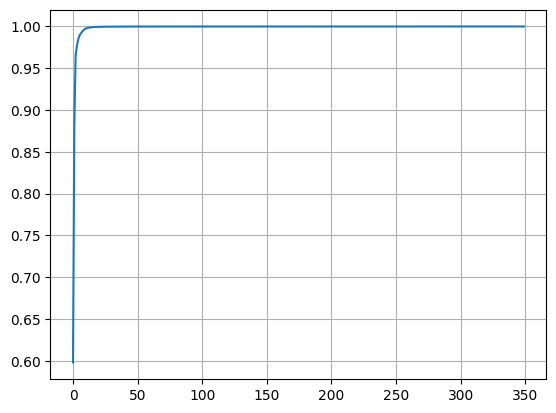

In [10]:
from sklearn.decomposition import PCA
pca = PCA() # initialise PCA with default parameters
x_pca = pca.fit_transform(xvals_train_std) # compute principal components and transforms data into new feature space
explained_variance_ratio = pca.explained_variance_ratio_  # Get explained variance ratio for each component
cumulative_explained_variance_ratio = np.cumsum(explained_variance_ratio) # sum computed variance for certain number of components
import matplotlib.pyplot as plt
plt.plot(cumulative_explained_variance_ratio) # plot cumulative explained variance ratio
plt.grid(True) # add grid to the plot
plt.show() # show graph

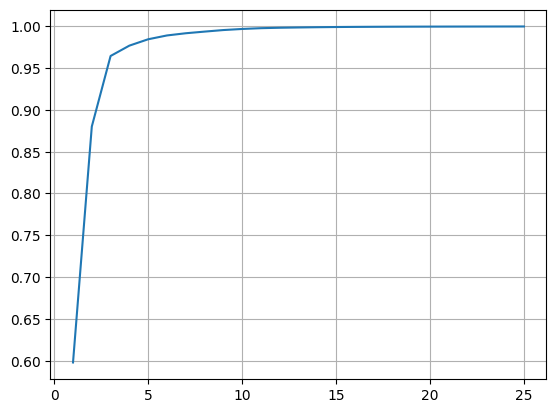

In [11]:
chosen_num_components = 25  # plateu cannot be read accurately so limit x axis to [0,25] and plot again
plt.plot(range(1, chosen_num_components + 1), cumulative_explained_variance_ratio[:chosen_num_components])
plt.grid(True) # add grid to the plot
plt.show() # plateu can be read

In [12]:
chosen_num_components = 3 # there is little to no change in cumulative variance when more than 3 principal components are involved in calculations
pca = PCA(n_components = chosen_num_components) # initialise new pca with no of components = 3
x_pca = pca.fit_transform(xvals_train_std) # compute principal components and transforms data into new feature space

Perform recursive feature selection (RFE)

In [13]:
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression # use logistic regression as estimator function to perfom RFE
rfe = RFE(estimator=LogisticRegression(), n_features_to_select=3, verbose=1) # 3 features selected as idenitified from PCA earlier
rfe.fit(xvals_train_std, yvals_train_binary) # identify rank of importance of features by comparing hyperparameters identified from the logistic regression model
significant_features_3 = list(xvals_train.columns[rfe.support_])
insignificant_features_3 = list(xvals_train.columns[~rfe.support_])
print(len(insignificant_features_3) + len(significant_features_3)) # check if total number of features is 350
print(insignificant_features_3) # identify insiginficant features identified with this technique



Fitting estimator with 350 features.
Fitting estimator with 349 features.
Fitting estimator with 348 features.
Fitting estimator with 347 features.
Fitting estimator with 346 features.
Fitting estimator with 345 features.
Fitting estimator with 344 features.
Fitting estimator with 343 features.
Fitting estimator with 342 features.
Fitting estimator with 341 features.
Fitting estimator with 340 features.
Fitting estimator with 339 features.
Fitting estimator with 338 features.
Fitting estimator with 337 features.
Fitting estimator with 336 features.
Fitting estimator with 335 features.
Fitting estimator with 334 features.
Fitting estimator with 333 features.
Fitting estimator with 332 features.
Fitting estimator with 331 features.


Fitting estimator with 330 features.
Fitting estimator with 329 features.
Fitting estimator with 328 features.
Fitting estimator with 327 features.
Fitting estimator with 326 features.
Fitting estimator with 325 features.
Fitting estimator with 324 features.
Fitting estimator with 323 features.
Fitting estimator with 322 features.
Fitting estimator with 321 features.
Fitting estimator with 320 features.
Fitting estimator with 319 features.
Fitting estimator with 318 features.
Fitting estimator with 317 features.
Fitting estimator with 316 features.
Fitting estimator with 315 features.
Fitting estimator with 314 features.
Fitting estimator with 313 features.
Fitting estimator with 312 features.
Fitting estimator with 311 features.
Fitting estimator with 310 features.


Fitting estimator with 309 features.
Fitting estimator with 308 features.
Fitting estimator with 307 features.
Fitting estimator with 306 features.
Fitting estimator with 305 features.
Fitting estimator with 304 features.
Fitting estimator with 303 features.
Fitting estimator with 302 features.
Fitting estimator with 301 features.
Fitting estimator with 300 features.
Fitting estimator with 299 features.
Fitting estimator with 298 features.
Fitting estimator with 297 features.
Fitting estimator with 296 features.
Fitting estimator with 295 features.
Fitting estimator with 294 features.
Fitting estimator with 293 features.
Fitting estimator with 292 features.
Fitting estimator with 291 features.
Fitting estimator with 290 features.
Fitting estimator with 289 features.
Fitting estimator with 288 features.
Fitting estimator with 287 features.
Fitting estimator with 286 features.


Fitting estimator with 285 features.
Fitting estimator with 284 features.
Fitting estimator with 283 features.
Fitting estimator with 282 features.
Fitting estimator with 281 features.
Fitting estimator with 280 features.
Fitting estimator with 279 features.
Fitting estimator with 278 features.
Fitting estimator with 277 features.
Fitting estimator with 276 features.
Fitting estimator with 275 features.
Fitting estimator with 274 features.
Fitting estimator with 273 features.
Fitting estimator with 272 features.
Fitting estimator with 271 features.
Fitting estimator with 270 features.
Fitting estimator with 269 features.
Fitting estimator with 268 features.
Fitting estimator with 267 features.
Fitting estimator with 266 features.
Fitting estimator with 265 features.
Fitting estimator with 264 features.
Fitting estimator with 263 features.
Fitting estimator with 262 features.
Fitting estimator with 261 features.


Fitting estimator with 260 features.
Fitting estimator with 259 features.
Fitting estimator with 258 features.
Fitting estimator with 257 features.
Fitting estimator with 256 features.
Fitting estimator with 255 features.
Fitting estimator with 254 features.
Fitting estimator with 253 features.
Fitting estimator with 252 features.
Fitting estimator with 251 features.
Fitting estimator with 250 features.
Fitting estimator with 249 features.
Fitting estimator with 248 features.
Fitting estimator with 247 features.
Fitting estimator with 246 features.
Fitting estimator with 245 features.
Fitting estimator with 244 features.
Fitting estimator with 243 features.
Fitting estimator with 242 features.
Fitting estimator with 241 features.
Fitting estimator with 240 features.
Fitting estimator with 239 features.
Fitting estimator with 238 features.
Fitting estimator with 237 features.


...

Fitting estimator with 209 features.
Fitting estimator with 208 features.
Fitting estimator with 207 features.
Fitting estimator with 206 features.
Fitting estimator with 205 features.
Fitting estimator with 204 features.
Fitting estimator with 203 features.
Fitting estimator with 202 features.
Fitting estimator with 201 features.
Fitting estimator with 200 features.
Fitting estimator with 199 features.
Fitting estimator with 198 features.
Fitting estimator with 197 features.
Fitting estimator with 196 features.
Fitting estimator with 195 features.
Fitting estimator with 194 features.
Fitting estimator with 193 features.
Fitting estimator with 192 features.
Fitting estimator with 191 features.
Fitting estimator with 190 features.
Fitting estimator with 189 features.
Fitting estimator with 188 features.
Fitting estimator with 187 features.
Fitting estimator with 186 features.
Fitting estimator with 185 features.
Fitting estimator with 184 features.
Fitting estimator with 183 features.
F

Fitting estimator with 179 features.
Fitting estimator with 178 features.
Fitting estimator with 177 features.
Fitting estimator with 176 features.
Fitting estimator with 175 features.
Fitting estimator with 174 features.
Fitting estimator with 173 features.
Fitting estimator with 172 features.
Fitting estimator with 171 features.
Fitting estimator with 170 features.
Fitting estimator with 169 features.
Fitting estimator with 168 features.
Fitting estimator with 167 features.
Fitting estimator with 166 features.
Fitting estimator with 165 features.
Fitting estimator with 164 features.
Fitting estimator with 163 features.
Fitting estimator with 162 features.
Fitting estimator with 161 features.
Fitting estimator with 160 features.
Fitting estimator with 159 features.
Fitting estimator with 158 features.
Fitting estimator with 157 features.
Fitting estimator with 156 features.
Fitting estimator with 155 features.
Fitting estimator with 154 features.
Fitting estimator with 153 features.
F

Fitting estimator with 145 features.
Fitting estimator with 144 features.
Fitting estimator with 143 features.
Fitting estimator with 142 features.
Fitting estimator with 141 features.
Fitting estimator with 140 features.
Fitting estimator with 139 features.
Fitting estimator with 138 features.
Fitting estimator with 137 features.
Fitting estimator with 136 features.
Fitting estimator with 135 features.
Fitting estimator with 134 features.
Fitting estimator with 133 features.
Fitting estimator with 132 features.
Fitting estimator with 131 features.
Fitting estimator with 130 features.
Fitting estimator with 129 features.
Fitting estimator with 128 features.
Fitting estimator with 127 features.
Fitting estimator with 126 features.
Fitting estimator with 125 features.
Fitting estimator with 124 features.
Fitting estimator with 123 features.
Fitting estimator with 122 features.
Fitting estimator with 121 features.
Fitting estimator with 120 features.
Fitting estimator with 119 features.
F

Fitting estimator with 103 features.
Fitting estimator with 102 features.
Fitting estimator with 101 features.
Fitting estimator with 100 features.
Fitting estimator with 99 features.
Fitting estimator with 98 features.
Fitting estimator with 97 features.
Fitting estimator with 96 features.
Fitting estimator with 95 features.
Fitting estimator with 94 features.
Fitting estimator with 93 features.
Fitting estimator with 92 features.
Fitting estimator with 91 features.
Fitting estimator with 90 features.
Fitting estimator with 89 features.
Fitting estimator with 88 features.
Fitting estimator with 87 features.
Fitting estimator with 86 features.
Fitting estimator with 85 features.
Fitting estimator with 84 features.
Fitting estimator with 83 features.
Fitting estimator with 82 features.
Fitting estimator with 81 features.
Fitting estimator with 80 features.
Fitting estimator with 79 features.
Fitting estimator with 78 features.
Fitting estimator with 77 features.
Fitting estimator with 7

Fitting estimator with 42 features.
Fitting estimator with 41 features.
Fitting estimator with 40 features.
Fitting estimator with 39 features.
Fitting estimator with 38 features.
Fitting estimator with 37 features.
Fitting estimator with 36 features.
Fitting estimator with 35 features.
Fitting estimator with 34 features.
Fitting estimator with 33 features.
Fitting estimator with 32 features.
Fitting estimator with 31 features.
Fitting estimator with 30 features.
Fitting estimator with 29 features.
Fitting estimator with 28 features.
Fitting estimator with 27 features.
Fitting estimator with 26 features.
Fitting estimator with 25 features.
Fitting estimator with 24 features.
Fitting estimator with 23 features.
Fitting estimator with 22 features.
Fitting estimator with 21 features.
Fitting estimator with 20 features.
Fitting estimator with 19 features.
Fitting estimator with 18 features.
Fitting estimator with 17 features.
Fitting estimator with 16 features.
Fitting estimator with 15 fe

Perform correlation analysis to identify insignifcant regressors that are are highly correlated

In [14]:
correlation_matrix = xvals_train.corr() # find correlation coefficients between each pair of variables
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool)) # mask to consider only the upper triangular matrix and ignore correlation between the same variable. Output is true and false
correlation_matrix = correlation_matrix.mask(mask) # apply mask to correlation matrix

In [15]:
def flag_correlated_features(correlation_matrix, threshold):
    values = correlation_matrix.abs().to_numpy() # upper triangle is NaN after masking
    columns = correlation_matrix.columns
    # flag feature i if it is highly correlated with any earlier feature j < i
    return [columns[i] for i in range(1, len(columns)) if np.nanmax(values[i, :i]) > threshold]

lengths_of_significant_features = [] # (threshold, number of features kept) for each threshold
for threshold_int in range(70, 101):
    threshold_float = threshold_int / 100.0
    kept = len(correlation_matrix.columns) - len(flag_correlated_features(correlation_matrix, threshold_float))
    lengths_of_significant_features.append((threshold_float, kept))

print(lengths_of_significant_features) # 2 features kept for thresholds 0.70-0.84 and 3 for 0.85-0.90, so choosing 0.8 has little effect

[(0.7, 2), (0.71, 2), (0.72, 2), (0.73, 2), (0.74, 2), (0.75, 2), (0.76, 2), (0.77, 2), (0.78, 2), (0.79, 2), (0.8, 2), (0.81, 2), (0.82, 2), (0.83, 2), (0.84, 2), (0.85, 3), (0.86, 3), (0.87, 3), (0.88, 3), (0.89, 3), (0.9, 3), (0.91, 5), (0.92, 5), (0.93, 6), (0.94, 6), (0.95, 6), (0.96, 6), (0.97, 6), (0.98, 7), (0.99, 9), (1.0, 350)]


In [16]:
insignificant_features_4 = flag_correlated_features(correlation_matrix, 0.8) # threshold of 0.8
significant_features_4 = [feature for feature in xvals_train.columns if feature not in insignificant_features_4]

print(len(insignificant_features_4) + len(significant_features_4))
print(insignificant_features_4)

350
['length_52', 'length_53', 'length_54', 'length_55', 'length_56', 'length_57', 'length_58', 'length_59', 'length_60', 'length_61', 'length_62', 'length_63', 'length_64', 'length_65', 'length_66', 'length_67', 'length_68', 'length_69', 'length_70', 'length_71', 'length_72', 'length_73', 'length_74', 'length_75', 'length_76', 'length_77', 'length_78', 'length_79', 'length_80', 'length_81', 'length_82', 'length_83', 'length_84', 'length_85', 'length_86', 'length_87', 'length_88', 'length_89', 'length_90', 'length_91', 'length_92', 'length_93', 'length_94', 'length_95', 'length_96', 'length_97', 'length_98', 'length_99', 'length_100', 'length_101', 'length_102', 'length_103', 'length_104', 'length_105', 'length_106', 'length_107', 'length_108', 'length_109', 'length_110', 'length_111', 'length_112', 'length_113', 'length_114', 'length_115', 'length_116', 'length_117', 'length_118', 'length_119', 'length_120', 'length_121', 'length_122', 'length_123', 'length_124', 'length_125', 'length

Decide which features to remove

Check lengths of features to be removed

In [17]:

removables = {}

def update_to_remove(insignificant_features):
    for feature in insignificant_features:
        if feature not in removables:
            removables[feature] = 0
        removables[feature] += 1
    return removables

update_to_remove(insignificant_features_1)
update_to_remove(insignificant_features_3)
update_to_remove(insignificant_features_4)

{'length_51': 2,
 'length_52': 3,
 'length_54': 3,
 'length_55': 3,
 'length_56': 3,
 'length_57': 3,
 'length_58': 3,
 'length_59': 3,
 'length_60': 2,
 'length_61': 3,
 'length_62': 3,
 'length_63': 3,
 'length_64': 3,
 'length_65': 3,
 'length_66': 3,
 'length_67': 3,
 'length_68': 3,
 'length_69': 3,
 'length_70': 3,
 'length_71': 3,
 'length_72': 3,
 'length_73': 3,
 'length_74': 3,
 'length_75': 3,
 'length_76': 3,
 'length_77': 3,
 'length_78': 3,
 'length_79': 3,
 'length_81': 3,
 'length_82': 3,
 'length_83': 3,
 'length_84': 3,
 'length_85': 3,
 'length_86': 3,
 'length_87': 3,
 'length_88': 3,
 'length_89': 3,
 'length_90': 3,
 'length_91': 3,
 'length_92': 3,
 'length_93': 3,
 'length_94': 3,
 'length_95': 3,
 'length_96': 3,
 'length_97': 3,
 'length_98': 3,
 'length_99': 3,
 'length_100': 3,
 'length_101': 3,
 'length_102': 3,
 'length_103': 3,
 'length_104': 3,
 'length_105': 3,
 'length_106': 3,
 'length_107': 3,
 'length_108': 3,
 'length_109': 3,
 'length_110': 3,
 'l

Find how many appearences the features appear in insiginficant features


In [18]:
drops_2 = []
drops_3 = []

for feature in removables:
    if removables[feature] >= 2:
        drops_2.append(feature)
    if removables[feature] >= 3:
        drops_3.append(feature)

print(len(drops_2)) # 348 variables removed # 2 variables preserved
print(len(drops_3)) # 333 variables removed # 17 variables preserved (flagged by all three methods)

348
333


Update data set by removing features in drop 3

In [19]:
### features in drops3 removed from train data set
xvals_train_filtered = xvals_train.drop(columns=drops_3)
print(xvals_train_filtered.shape)

### features in drops3 removed from test data set
xvals_test_filtered = xvals_test.drop(columns=drops_3)
print(xvals_test_filtered.shape)


# xvals_train_filtered to be used as dependent variables used to build the model
# xvals_test_filtered to be used as dependent variables used to build the model

# xvals_train_std are the standardised dependent values
# xvals_test_std are the standardised dependent values

# yvals_train_binary are the binary values for the response variable
# yvals_test_binary are the binary values for the response variable

### oriignal data
# xvals_train is the train set dependent variables
# xvals_test is the test set dependent variables
# yvals_train is the train set independent variables
# yvals_test is the test set independent variables





(550, 17)
(271, 17)
